# Model training

Training changes the weights of a model so that what it computes matches what
it should. In *nnodely* what it should match is stated as **objectives**:
`minimize(name, source, target, loss)` compares two streams of the graph, and
`train` minimizes the sum of all of them.

This tutorial identifies a dynamic system from data and shows:

- how objectives are declared, with every kind of target;
- how `train` is called: epochs, batches, learning rate, validation data;
- optimizers, loss functions, and weights between objectives;
- early stopping, the training printers, and the result of training;
- how to freeze parameters, change objectives, and train again.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    DataLoader,
    Fir,
    Input,
    Modely,
    Output,
    TimeRange,
    TimeSelect,
    set_seed,
)

set_seed(0)

## The system to identify

A second-order discrete system, driven by a piecewise-constant input:

$$y[t+1] = 1.5\,y[t] - 0.7\,y[t-1] + 0.5\,u[t] + \text{noise}$$

The model will have to find the coefficients `1.5`, `-0.7` and `0.5` from the
recorded `u` and `y` alone.

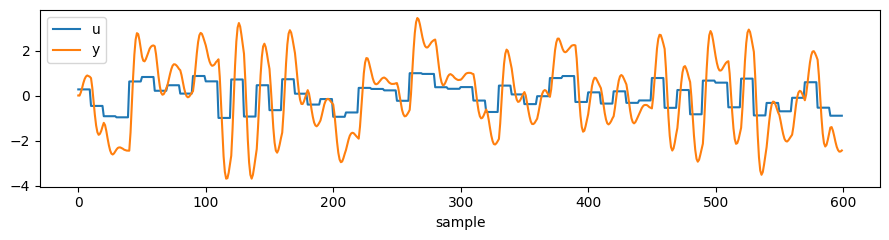

In [2]:
rng = np.random.default_rng(0)
T, dt = 3000, 0.1
u_data = np.repeat(rng.uniform(-1.0, 1.0, T // 10), 10)
y_data = np.zeros(T)
for t in range(1, T - 1):
    y_data[t + 1] = 1.5 * y_data[t] - 0.7 * y_data[t - 1] + 0.5 * u_data[t]
y_data += 0.005 * rng.standard_normal(T)

plt.figure(figsize=(9, 2.5))
plt.plot(u_data[:600], label="u")
plt.plot(y_data[:600], label="y")
plt.legend()
plt.xlabel("sample")
plt.tight_layout()

## The model and its objective

The model reads the last two samples of `y` and of `u`, and predicts the next
`y`. Each signal goes through a `Fir`: a weighted sum of its window, whose
kernel is exactly the coefficients of the equation (oldest sample first).

`y` is declared with one sample after the current one, `tw=(2, 1)`: the window
holds `y[t-1], y[t], y[t+1]`. The prediction reads the first two, and the third
is the **target**.

In [3]:
y = Input("y", tw=(2, 1))
u = Input("u", tw=2)

ar = Fir(features=1, bias=False, name="ar")([TimeRange(0, 2)(y)])  # y[t-1], y[t]
ex = Fir(features=1, bias=False, name="ex")([u])  # u[t-1], u[t]
y_next = Output("y_next", ar + ex)

model = Modely("arx", inputs=[y, u], outputs=[y_next])
model.minimize("one_step", y_next, TimeSelect(-1)(y), loss="mse")
model.minimizers

┏━━━━━┳━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ idx ┃ minimizer ┃ source ┃ target      ┃ loss               ┃ gain ┃
┡━━━━━╇━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ 0   │ one_step  │ y_next │ TimeSelect3 │ mean_squared_error │ 1.0  │
└─────┴───────────┴────────┴─────────────┴────────────────────┴──────┘

`minimize(name, source, target, loss)`:

- `name` identifies the objective: its loss is logged under `loss_<name>`;
- `source` is what the model computes - an `Output`, or any stream of the
  graph;
- `target` is what it should be. Here `TimeSelect(-1)(y)`, the last sample of
  the window of `y`, `y[t+1]`;
- `loss` compares them: `"mse"` by default.

Objectives are part of the graph that is built, so they are declared **before**
`build()`. A target-only input - one the model reads only as a target - is found
by the build; the data must hold it, inference does not need it.

In [4]:
model.build()

split = int(0.8 * T)
train_data = DataLoader(model, source={"y": y_data[:split], "u": u_data[:split]})
val_data = DataLoader(model, source={"y": y_data[split:], "u": u_data[split:]})
print(len(train_data), "training samples,", len(val_data), "validation samples")

2398 training samples, 598 validation samples


## Training

`train` runs the optimizer over the training data for a number of `epochs`, in
batches of `batch_size` samples, with learning rate `lr` (Adam by default).
With `val_data` it also reports the losses on the validation data after each
epoch. **Always set `epochs` and `batch_size`**: the defaults, 10 and 1, are
rarely what you want.

In [ ]:
trained = model.train(train_data, val_data=val_data, epochs=40, batch_size=32, lr=3e-2)

`train` returns a `TrainResult`, read by its attributes. `losses` holds an array
per key, one value per epoch: `loss` is the total of the objectives,
`loss_<name>` each one, and the `val_` versions the same on the validation data.
`print(trained)` shows the last losses of every objective. The model does not
keep the result: save it in a variable.

In [ ]:
print(trained)
print(trained.losses.keys())

plt.figure(figsize=(6, 3))
plt.semilogy(trained.losses["loss"], label="train")
plt.semilogy(trained.losses["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()

The weights of a `Fir` are `Parameter`s, listed by the model with their current
values. The kernels hold the coefficients, oldest sample first:
`[-0.7, 1.5]` for `y` and `[0, 0.5]` for `u`.

In [7]:
print("y kernel:", model.parameters["ar_kernel"].value_numpy.ravel().round(3))
print("u kernel:", model.parameters["ex_kernel"].value_numpy.ravel().round(3))

y kernel: [-0.7  1.5]
u kernel: [0.001 0.5  ]


## Targets

A target can be any of these:

| Target | Example | Use |
|---|---|---|
| an `Input` | `Input("y_meas", tw=1)` | a separate measured column |
| a part of a window | `TimeSelect(-1)(y)` | the sample after the ones the model reads |
| a stream computed from data | `(TimeSelect(-1)(y) - TimeSelect(-2)(y)) / dt` | a derived quantity |
| a number | `0.0` | drive the source to a value |
| `None` | `minimize("law", residual)` | drive a residual to zero (a physical law) |

A target read from data must have exactly the shape of the source; a number is
broadcast to it.

## Several objectives, and their weights

A model can have any number of objectives: `train` minimizes the sum of their
losses, each weighted by its `gain`. Here a second objective asks the predicted
velocity - from the current to the predicted position - to match the measured
one, computed from the data:

In [8]:
y_now = TimeSelect(-2)(y)
velocity = (y_next - y_now) / dt
measured_velocity = (TimeSelect(-1)(y) - y_now) / dt
model.minimize("velocity", velocity, measured_velocity, loss="mae", gain=0.01)
model.build()  # objectives are part of the graph: build again
model.minimizers

┏━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ idx ┃ minimizer ┃ source  ┃ target      ┃ loss                ┃ gain ┃
┡━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ 0   │ one_step  │ y_next  │ TimeSelect3 │ mean_squared_error  │ 1.0  │
│ 1   │ velocity  │ Divide6 │ Divide10    │ mean_absolute_error │ 0.01 │
└─────┴───────────┴─────────┴─────────────┴─────────────────────┴──────┘

`gain` weighs the objective in the total loss - velocities are 10 times larger
than positions here - while its logged loss stays unweighted, so the losses of
two objectives can be compared as they are.

## Optimizers and losses

`optimizer` is a Keras optimizer: a name (`"adam"`, `"sgd"`, `"rmsprop"`,
`"adamw"`, ...) configured by `lr` and `optimizer_kwargs`, or an instance you
configure yourself. `loss` is a Keras loss: a name (`"mse"`, `"mae"`,
`"huber"`, `"log_cosh"`, ...), a `keras.losses.Loss`, or any function
`loss(y_true, y_pred)`.

In [ ]:
def relative_error(y_true, y_pred):
    return keras.ops.abs(y_pred - y_true) / (keras.ops.abs(y_true) + 1.0)


model.minimize(
    "one_step", y_next, TimeSelect(-1)(y), loss=keras.losses.Huber(delta=0.1)
)
model.minimize("relative", y_next, TimeSelect(-1)(y), loss=relative_error, gain=0.1)
model.build()

trained = model.train(
    train_data,
    val_data=val_data,
    epochs=5,
    batch_size=32,
    optimizer="adamw",
    lr=5e-3,
    optimizer_kwargs={"weight_decay": 1e-4, "global_clipnorm": 1.0},
    printer=None,
)
print({name: round(float(values[-1]), 6) for name, values in trained.losses.items()})

Declaring an objective with a name already taken replaces it, as `one_step` was
here, with a warning. The objectives are listed by `model.minimizers`, and
changed or removed there:

In [10]:
model.minimizers["relative"].gain = 0.5  # from the next train(), no build needed
model.remove_minimizer("relative")
model.minimizers

┏━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ idx ┃ minimizer ┃ source  ┃ target       ┃ loss                ┃ gain ┃
┡━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ 0   │ one_step  │ y_next  │ TimeSelect11 │ huber_loss          │ 1.0  │
│ 1   │ velocity  │ Divide6 │ Divide10     │ mean_absolute_error │ 0.01 │
└─────┴───────────┴─────────┴──────────────┴─────────────────────┴──────┘

An instance is passed as it is (`lr` and `optimizer_kwargs` only configure
names). Every `train` continues from the current weights:

In [ ]:
model.build()  # one objective fewer
trained = model.train(
    train_data,
    val_data=val_data,
    epochs=5,
    batch_size=64,
    optimizer=keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9),
    printer=None,
)
print("val loss:", round(float(trained.losses["val_loss"][-1]), 6))

## Early stopping

`early_stopping` names a logged quantity to watch - `"val_loss"`, or the loss
of one objective, `"val_loss_one_step"` - and stops when it stops improving.
`early_stopping_kwargs` configures Keras' `EarlyStopping`: `patience`,
`restore_best_weights`, `min_delta`, ... Any Keras callback that sets
`model.stop_training` works too.

In [ ]:
trained = model.train(
    train_data,
    val_data=val_data,
    epochs=200,
    batch_size=32,
    lr=1e-3,
    early_stopping="val_loss",
    early_stopping_kwargs={"patience": 3, "restore_best_weights": True},
    printer=None,
)
print("stopped after", trained.epochs, "of 200 epochs")

## Printers

`printer` chooses how training is reported:

| `printer` | Shows |
|---|---|
| `"legacy"` (default) | a table, a row per sampled epoch and the training time |
| `"tiny"` | one line, updated in place |
| `"nnodely"` | an animated panel with a chart of the loss |
| `None` | nothing - for scripts and tests |
| a `keras.callbacks.Callback` | your own |

In [ ]:
trained = model.train(
    train_data, val_data=val_data, epochs=10, batch_size=32, lr=1e-3, printer="tiny"
)

## Freezing parameters

A frozen `Parameter` keeps its value through training. Freeze them by name
from the model, one by itself, or all at once; `unfreeze` releases them. The
`trainable` column of `parameters` shows the state.

In [14]:
model.freeze("ex_kernel")  # by name
before = model.parameters["ex_kernel"].value_numpy.copy()
model.train(train_data, epochs=3, batch_size=32, lr=1e-2, printer=None)
print("unchanged:", np.array_equal(before, model.parameters["ex_kernel"].value_numpy))
model.parameters

unchanged: True


┏━━━━━┳━━━━━━━━━━━┳━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ idx ┃ parameter ┃ seq ┃ tw   ┃ dim    ┃ values ┃ trainable ┃
┡━━━━━╇━━━━━━━━━━━╇━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ 0   │ ar_kernel │ ()  │ None │ (2, 1) │ 2      │ yes       │
│ 1   │ ex_kernel │ ()  │ None │ (2, 1) │ 2      │ no        │
├─────┼───────────┼─────┼──────┼────────┼────────┼───────────┤
│     │ total     │     │      │        │ 4      │ 2         │
└─────┴───────────┴─────┴──────┴────────┴────────┴───────────┘

In [15]:
model.unfreeze()  # every parameter again
model.parameters["ar_kernel"].freeze()  # one parameter by itself
print({parameter.name: parameter.trainable for parameter in model.parameters})

{'ar_kernel': False, 'ex_kernel': True}


`unfreeze` releases them, here every one:

In [16]:
model.unfreeze()
print({parameter.name: parameter.trainable for parameter in model.parameters})

{'ar_kernel': True, 'ex_kernel': True}


## Starting again, and reproducibility

`build(keep_weights=False)` gives every weight its initial value back, to train
from scratch. `set_seed(n)`, called before the layers are created, makes the
initial weights, the shuffling and every result the same on every run.

## Summary

| Task | Code |
|---|---|
| Declare an objective | `model.minimize("name", source, target, loss="mse", gain=1.0)`, then `build()` |
| Train | `model.train(train, val_data=val, epochs=50, batch_size=32, lr=1e-3)` |
| Optimizer | `optimizer="adamw"`, `optimizer_kwargs={...}`, or an instance |
| Loss | a name, a `keras.losses.Loss`, or `f(y_true, y_pred)` |
| Weights | `gain=` per objective; logged losses stay unweighted |
| Stop early | `early_stopping="val_loss", early_stopping_kwargs={"patience": 10}` |
| Report | `printer="legacy" / "tiny" / "nnodely" / None` |
| Freeze | `model.freeze("name")`, `parameter.freeze()`, `model.unfreeze()` |
| Change objectives | `model.minimizers["name"].gain = ...`, `remove_minimizer(...)` |
| Reset | `model.build(keep_weights=False)`; `set_seed(n)` for reproducibility |

Next: [Model validation](04_model_validation.ipynb) scores the trained model.